
# Exploratory Data Analysis (EDA)
## Teen Mental Health Dataset

### Project Objective
The objective of this analysis is to explore the Teen Mental Health dataset, understand its characteristics, identify patterns and relationships between variables, and extract meaningful insights before building machine learning models.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("Teen_Mental_Health_Dataset.csv")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())


Dataset shape: (2500, 12)


,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,depression_risk
0,19,male,3.8,Instagram,6.5,1.7,2.77,1.2,low,6,6,medium
1,16,male,6.5,Other,5.8,0.6,2.57,0.2,medium,9,7,high
2,17,female,2.9,Other,7.0,1.2,3.04,1.7,high,3,2,low
3,19,female,7.9,TikTok,5.0,1.6,2.21,1.2,medium,10,8,medium
4,15,female,1.2,TikTok,8.8,0.9,3.61,1.9,high,1,2,low


In [4]:

print("COLUMN NAMES AND DATA TYPES")
display(df.dtypes)

print("\nMISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())


COLUMN NAMES AND DATA TYPES


age                           int64
gender                       object
daily_social_media_hours    float64
platform_usage               object
sleep_hours                 float64
screen_time_before_sleep    float64
academic_performance        float64
physical_activity           float64
social_interaction_level     object
stress_level                  int64
anxiety_level                 int64
depression_risk              object
dtype: object


MISSING VALUES


age                         0
gender                      0
daily_social_media_hours    0
platform_usage              0
sleep_hours                 0
screen_time_before_sleep    0
academic_performance        0
physical_activity           0
social_interaction_level    0
stress_level                0
anxiety_level               0
depression_risk             0
dtype: int64


DUPLICATE ROWS
Number of duplicate rows: 0

DESCRIPTIVE STATISTICS


,age,daily_social_media_hours,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,stress_level,anxiety_level
count,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,15.978000,4.45804,6.192440,1.714760,2.890944,0.991760,5.596400,5.164800
std,2.003577,2.01693,1.018734,0.716636,0.559553,0.586963,3.039013,3.002473
min,13.000000,1.00000,4.000000,0.500000,2.000000,0.000000,1.000000,1.000000
25%,14.000000,2.70000,5.500000,1.100000,2.420000,0.500000,3.000000,2.000000
50%,16.000000,4.40000,6.200000,1.700000,2.880000,1.000000,6.000000,5.000000
75%,18.000000,6.20000,6.900000,2.300000,3.340000,1.500000,8.000000,8.000000
max,19.000000,8.00000,9.000000,3.000000,4.000000,2.000000,10.000000,10.000000


Depression Risk Counts:


depression_risk
high       584
low       1266
medium     650
Name: count, dtype: int64


Percentages:


depression_risk
high      23.36
low       50.64
medium    26.00
Name: proportion, dtype: float64

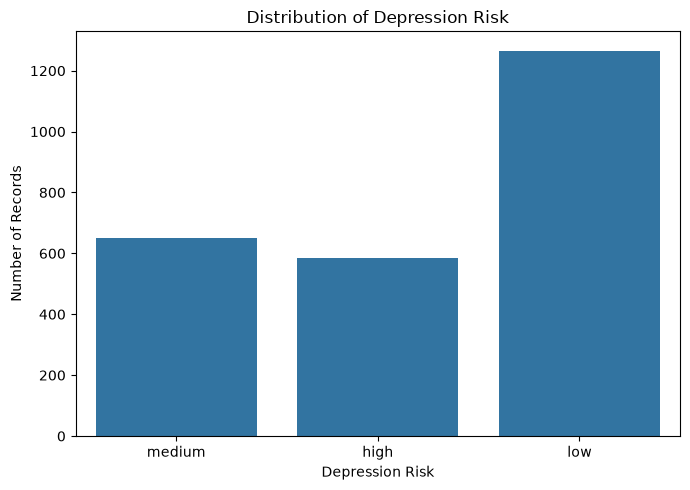

In [7]:

# Depression risk Distribution

label_counts = df["depression_risk"].value_counts().sort_index()

print("Depression Risk Counts:")
display(label_counts)

print("\nPercentages:")
display((df["depression_risk"].value_counts(normalize=True)
         .sort_index() * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="depression_risk")
plt.title("Distribution of Depression Risk")
plt.xlabel("Depression Risk")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


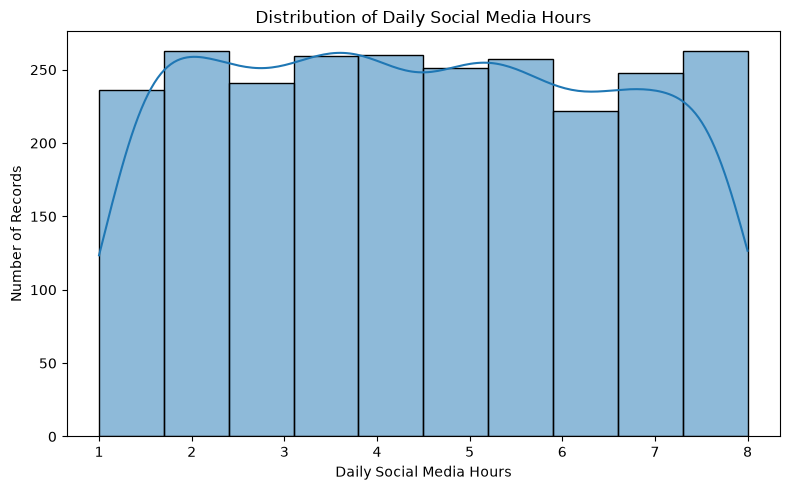

In [9]:

# daily_social_media_hours  Distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="daily_social_media_hours",
             bins=10, kde=True)

plt.title("Distribution of Daily Social Media Hours")
plt.xlabel("Daily Social Media Hours")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


Average Values by Depression Risk:


,sleep_hours,daily_social_media_hours,stress_level,anxiety_level
depression_risk,,,,
high,5.23,6.60,9.11,8.49
low,6.85,2.97,3.17,2.87
medium,5.78,5.42,7.16,6.65


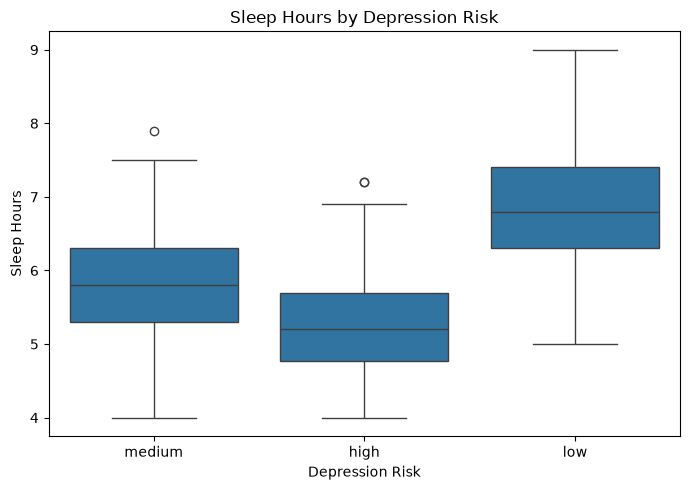

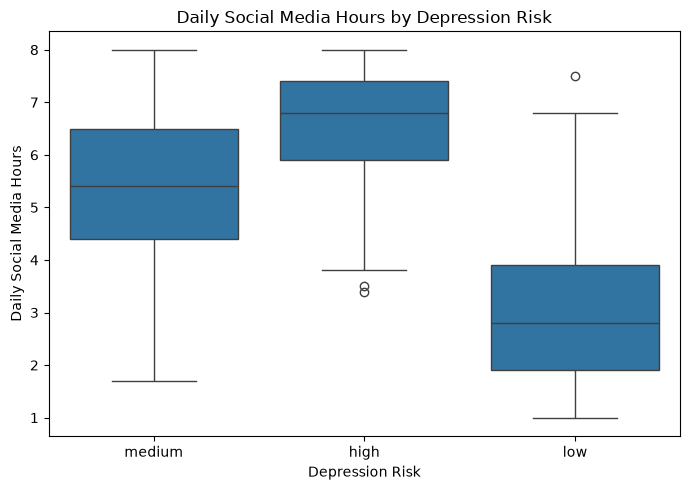

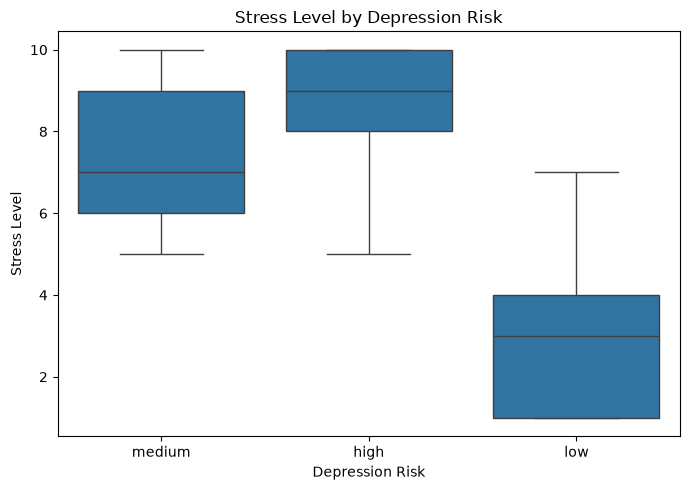

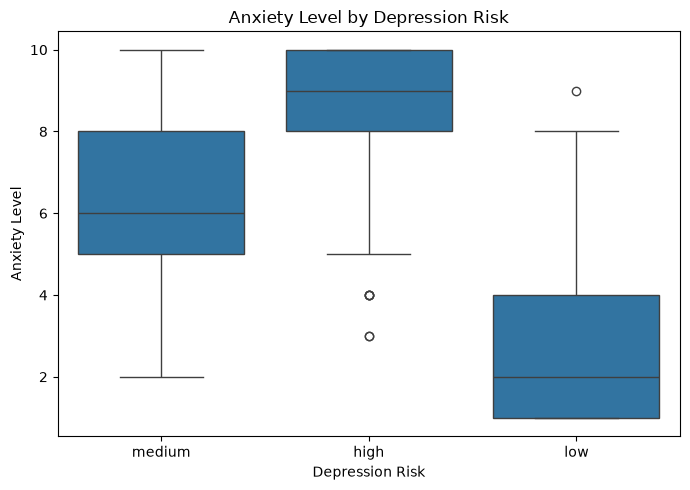

In [10]:

# Compare Numerical Features by Depression risk

features_to_compare = [
    "sleep_hours",
    "daily_social_media_hours",
    "stress_level",
    "anxiety_level"
]

print("Average Values by Depression Risk:")
display(
    df.groupby("depression_risk")[features_to_compare]
    .mean()
    .round(2)
)

for column in features_to_compare:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="depression_risk", y=column)
    plt.title(f"{column.replace('_', ' ').title()} by Depression Risk")
    plt.xlabel("Depression Risk")
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()
